In [1]:
import pandas as pd

train = pd.read_csv("../data/train.csv")
test = pd.read_csv("../data/test.csv")

X_train = train.drop(columns=["subject", "Activity"])
y_train = train["Activity"]
X_test = test.drop(columns=["subject", "Activity"])
y_test = test["Activity"]

print(X_train.shape, X_test.shape)

(7352, 561) (2947, 561)


In [2]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

tree = DecisionTreeClassifier(random_state=42).fit(X_train, y_train)
forest = RandomForestClassifier(random_state=42).fit(X_train, y_train)

print("Decision Tree:", accuracy_score(y_test, tree.predict(X_test)))
print("Random Forest:", accuracy_score(y_test, forest.predict(X_test)))

Decision Tree: 0.8622327790973872
Random Forest: 0.9267051238547676


In [3]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5).fit(X_train, y_train)
print("KNN:", accuracy_score(y_test, knn.predict(X_test)))

KNN: 0.9002375296912114


In [4]:
for k in [3, 5, 7, 11]:
    knn = KNeighborsClassifier(n_neighbors=k).fit(X_train, y_train)
    print("K =", k, ":", accuracy_score(y_test, knn.predict(X_test)))

K = 3 : 0.8907363420427553
K = 5 : 0.9002375296912114
K = 7 : 0.9022734984730234
K = 11 : 0.9039701391245334


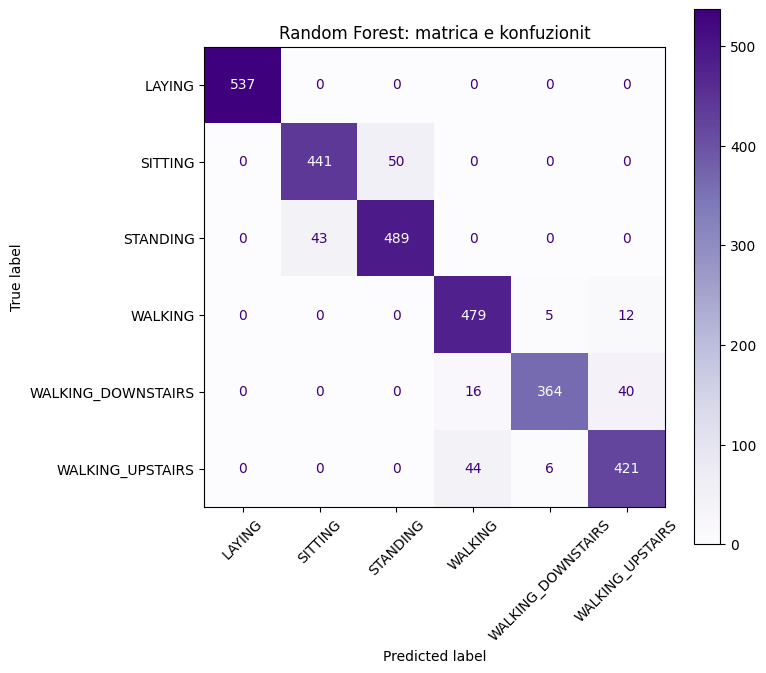

In [5]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay.from_estimator(
    forest, X_test, y_test, ax=ax, xticks_rotation=45, cmap="Purples"
)
plt.title("Random Forest: matrica e konfuzionit")
plt.tight_layout()
plt.show()

In [6]:
from sklearn.metrics import classification_report

print(classification_report(y_test, forest.predict(X_test)))

                    precision    recall  f1-score   support

            LAYING       1.00      1.00      1.00       537
           SITTING       0.91      0.90      0.90       491
          STANDING       0.91      0.92      0.91       532
           WALKING       0.89      0.97      0.93       496
WALKING_DOWNSTAIRS       0.97      0.87      0.92       420
  WALKING_UPSTAIRS       0.89      0.89      0.89       471

          accuracy                           0.93      2947
         macro avg       0.93      0.92      0.93      2947
      weighted avg       0.93      0.93      0.93      2947



In [7]:
import joblib
joblib.dump(forest, "../model.joblib")

['../model.joblib']